In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from google.colab import files

SEED = 42

print("Pilih dan upload berkas healthcare-dataset-stroke-data.csv :")
uploaded = files.upload()

# Mengambil file yang akan di-upload
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)
print(f"\nData Berhasil Dimuat! Total baris: {df.shape[0]}, Total kolom: {df.shape[1]}")
df.head()

Pilih dan upload berkas healthcare-dataset-stroke-data.csv :


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (3).csv

Data Berhasil Dimuat! Total baris: 5110, Total kolom: 12


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Ispeksi Detail Dataset & Missing Values

In [ ]:
print("=== 1. DISTRIBUSI TARGET STROKE ===")
stroke_counts = df['stroke'].value_counts()
print(stroke_counts)
print(f"Total: {len(df)} baris, Kasus Stroke: {stroke_counts[1]} ({(stroke_counts[1] / len(df)) * 100:.2f}%)\n")

print("=== 2. DISTRIBUSI GENDER ===")
print(df['gender'].value_counts(), "\n")

print("=== 3. ANALISIS MISSING VALUE BMI ===")
null_bmi = df[df['bmi'].isnull()]
print(f"Total baris BMI kosong: {len(null_bmi)}")
print(f"Jumlah pasien stroke dengan BMI kosong: {null_bmi['stroke'].sum()} orang")
print("--> KESIMPULAN: Jangan hapus 201 baris ini karena mengandung pasien stroke!\n")

print("=== 4. ANALISIS SMOKING STATUS (UNKNOWN) ===")
print(df['smoking_status'].value_counts())
print(f"Persentase Unknown: {(df['smoking_status'].value_counts()['Unknown'] / len(df)) * 100:.2f}%")

=== 1. DISTRIBUSI TARGET STROKE ===
stroke
0    4861
1     249
Name: count, dtype: int64
Total: 5110 baris, Kasus Stroke: 249 (4.87%)

=== 2. DISTRIBUSI GENDER ===
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

=== 3. ANALISIS MISSING VALUE BMI ===
Total baris BMI kosong: 201
Jumlah pasien stroke dengan BMI kosong: 40 orang
--> KESIMPULAN: Jangan hapus 201 baris ini karena mengandung pasien stroke!

=== 4. ANALISIS SMOKING STATUS (UNKNOWN) ===
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64
Persentase Unknown: 30.22%


Visualisais EDA

/tmp/ipykernel_721/2138400865.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='stroke', data=df, ax=axes[0], palette='Set2')


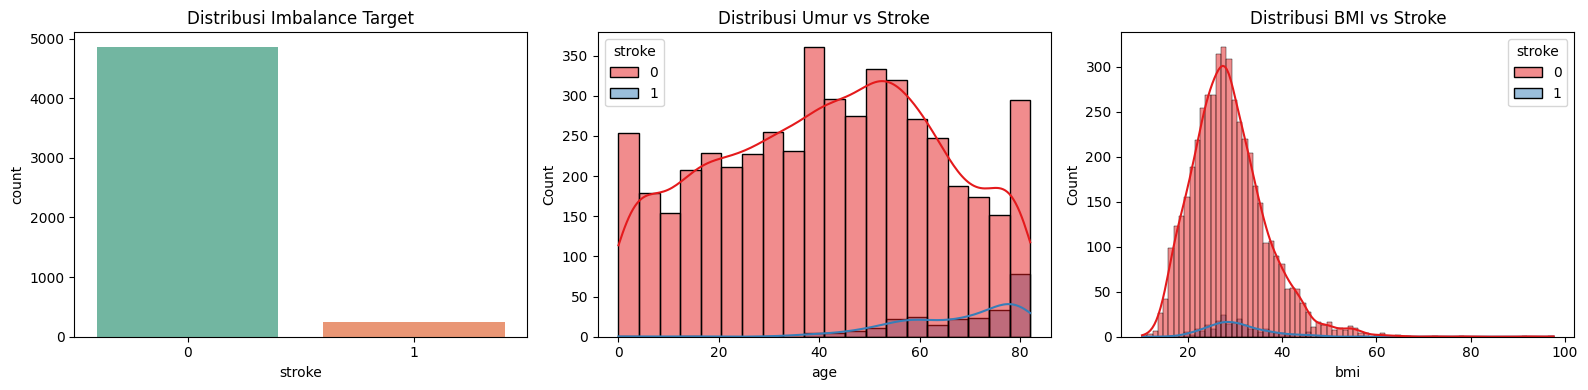

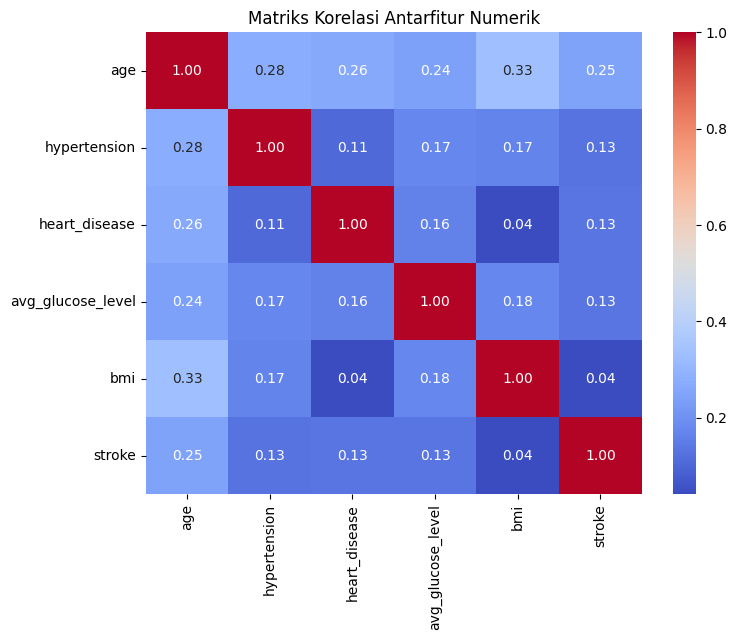

In [ ]:
# 1. Histogram & Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x='stroke', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi Imbalance Target')

sns.histplot(data=df, x='age', hue='stroke', kde=True, ax=axes[1], palette='Set1')
axes[1].set_title('Distribusi Umur vs Stroke')

sns.histplot(data=df, x='bmi', hue='stroke', kde=True, ax=axes[2], palette='Set1')
axes[2].set_title('Distribusi BMI vs Stroke')

plt.tight_layout()
plt.show()

# 2. Korelasi Antarfitur Numerik (Heatmap)
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['id'], errors='ignore')
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Antarfitur Numerik')
plt.show()

Cleaning Data & Imputasi

In [ ]:
# 1. Buang kolom 'id'
df_clean = df.drop(columns=['id']).copy()

# 2. Buang 1 baris gender = "Other"
df_clean = df_clean[df_clean['gender'] != 'Other']

# 3. Imputasi nilai BMI yang kosong menggunakan Median
bmi_median = df_clean['bmi'].median()
df_clean['bmi'] = df_clean['bmi'].fillna(bmi_median)

# Separasi Fitur (X) dan Target (y)
X = df_clean.drop(columns=['stroke'])
y = df_clean['stroke']

print(f"Cleaning selesai! Ukuran X: {X.shape}, Ukuran y: {y.shape}")

Cleaning selesai! Ukuran X: (5109, 10), Ukuran y: (5109,)


Stratified Split 70/15/15

In [ ]:
# Split 1: 70% Train, 30% Temp (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Split 2: Bagi Temp 30% menjadi 15% Val dan 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("=== HASIL STRATIFIED SPLIT 70/15/15 ===")
print(f"Train : {X_train.shape[0]} baris | Pasien Stroke: {y_train.sum()}")
print(f"Val   : {X_val.shape[0]} baris  | Pasien Stroke: {y_val.sum()}")
print(f"Test  : {X_test.shape[0]} baris  | Pasien Stroke: {y_test.sum()}")

=== HASIL STRATIFIED SPLIT 70/15/15 ===
Train : 3576 baris | Pasien Stroke: 174
Val   : 766 baris  | Pasien Stroke: 37
Test  : 767 baris  | Pasien Stroke: 38


Scaling & Encoding

In [ ]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
cat_cols = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# FIT HANYA DI X_TRAIN!
X_train_proc = preprocessor.fit_transform(X_train)

# Data Val & Test HANYA di-transform
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print(f"Preprocessing selesai! Dimensi data latih akhir: {X_train_proc.shape}")

Preprocessing selesai! Dimensi data latih akhir: (3576, 15)


In [ ]:
# Simpan dataset ke format .npz
np.savez('train.npz', X=X_train_proc, y=y_train.values)
np.savez('val.npz', X=X_val_proc, y=y_val.values)
np.savez('test.npz', X=X_test_proc, y=y_test.values)

# Simpan objek preprocessor ke format .joblib
joblib.dump(preprocessor, 'preprocessor.joblib')

print("=== FILE BERHASIL DIEKSPOR ===")
print("File berikut siap diunduh dari folder Colab:")
print("1. train.npz")
print("2. val.npz")
print("3. test.npz")
print("4. preprocessor.joblib")

=== FILE BERHASIL DIEKSPOR ===
File berikut siap diunduh dari folder Colab:
1. train.npz
2. val.npz
3. test.npz
4. preprocessor.joblib
